In [48]:
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

In [56]:
df = pd.read_csv("data/CleanedLifeInsurance.csv")
X = df.drop(columns = ['POLICY STATUS', 'is_lapse'])
Y = df['is_lapse']
X = pd.get_dummies(X, drop_first = True, columns = ['SEX', 'POLICY TYPE 3', 'PAYMENT MODE', 'NON LAPSE GUARANTEED', 'Full Benefit?', 'Issue Date'])
Y = pd.get_dummies(Y, drop_first = False)
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.3, random_state=42)

In [57]:
model = XGBClassifier(n_estimators=2, max_depth=2, learning_rate=1, objective='binary:logistic')
model.fit(X_train, Y_train)
Y_pred = model.predict(X_test)

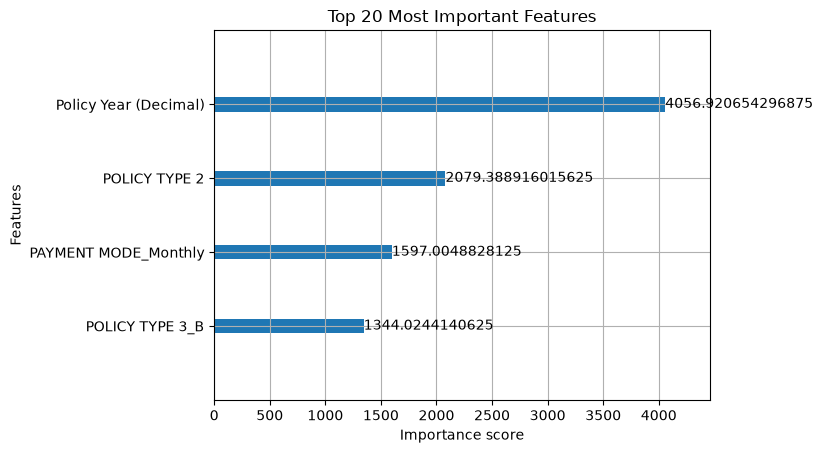

In [65]:
from xgboost import plot_importance

#plt.figure(figsize=(12, 8))

plot_importance(
    model,
    max_num_features=10,
    importance_type='gain'
)

plt.title("Top 20 Most Important Features")
plt.show()

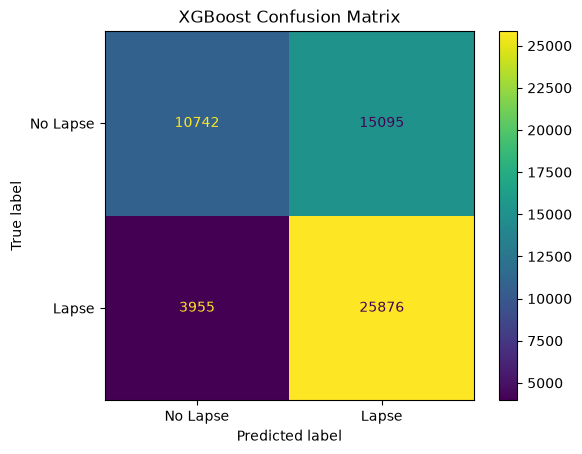

In [67]:
from sklearn.metrics import ConfusionMatrixDisplay

Y_test_labels = np.argmax(Y_test, axis=1)
Y_pred_labels = np.argmax(Y_pred, axis=1)

ConfusionMatrixDisplay.from_predictions(
    Y_test_labels,
    Y_pred_labels,
    display_labels = ['No Lapse', 'Lapse']
)

plt.title("XGBoost Confusion Matrix")
plt.show()